# Mobile Price Classification

**Objectif :** prédire la gamme de prix d'un téléphone (`price_range`, de 0 = économique à 3 = très cher) à partir de ses caractéristiques techniques (RAM, batterie, résolution, etc.).

C'est un problème de **classification multiclasse** : il y a 4 classes possibles.

**Dataset :** [Mobile Price Classification (Kaggle)](https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification) : 2000 téléphones, 20 caractéristiques, aucune valeur manquante.

**Démarche :**
1. Explorer les données (EDA)
2. Entraîner 3 modèles de base (Régression logistique, Arbre de décision, Random Forest)
3. Les optimiser avec `GridSearchCV`
4. Comparer les résultats et les confirmer par validation croisée
5. Conclure

## 1. Imports et chargement des données

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
train_df = pd.read_csv("data/train.csv")

In [3]:
train_df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [4]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_screen   2000

Vérifions la répartition des classes, les valeurs manquantes et les doublons :

In [5]:
train_df["price_range"].value_counts().sort_index()

price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64

In [6]:
train_df.isnull().sum()

battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64

In [7]:
train_df.duplicated().sum()

np.int64(0)

**Ce qu'on constate :**
- Les 4 classes ont exactement le même nombre de téléphones (500 chacune) : le dataset est **équilibré**, donc l'accuracy est une métrique fiable.
- Aucune valeur manquante, aucun doublon.

Statistiques descriptives de chaque variable :

In [8]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0


## 2. Analyse exploratoire (EDA)

On cherche quelles caractéristiques semblent liées au prix.

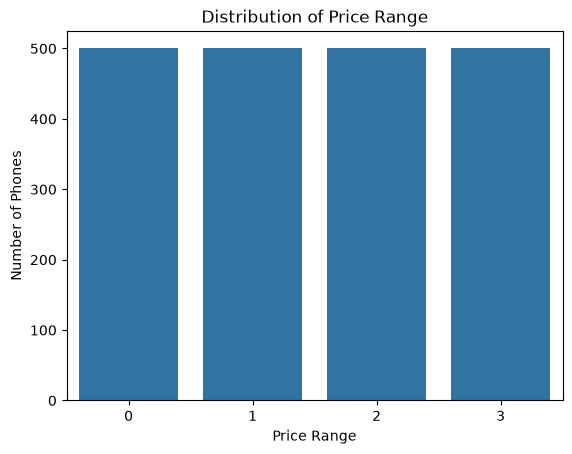

In [9]:
sns.countplot(data=train_df, x="price_range")

plt.title("Distribution of Price Range")
plt.xlabel("Price Range")
plt.ylabel("Number of Phones")
plt.show()

**La RAM** : elle augmente nettement avec la gamme de prix. C'est la variable qui sépare le mieux les classes.

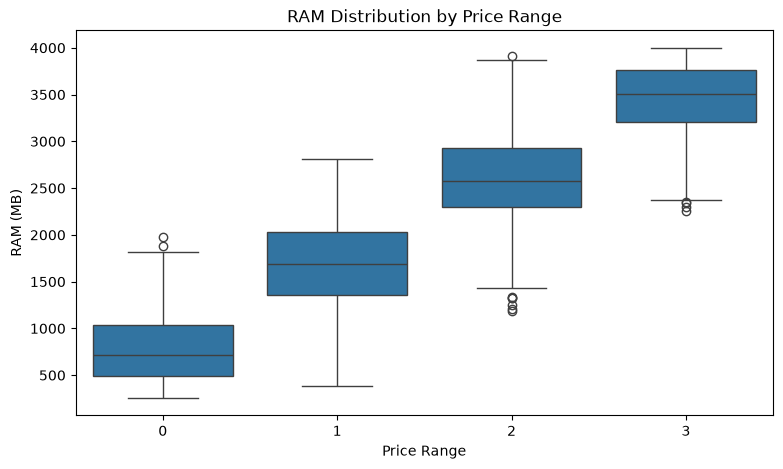

In [10]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=train_df,
    x="price_range",
    y="ram"
)

plt.title("RAM Distribution by Price Range")
plt.xlabel("Price Range")
plt.ylabel("RAM (MB)")
plt.show()

**La batterie** : tendance plus faible, les différences entre classes sont modestes.

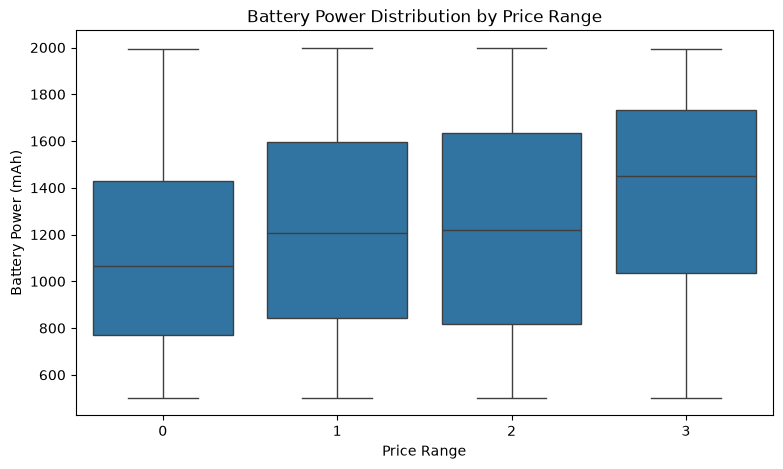

In [11]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=train_df, x="price_range", y="battery_power")

plt.title("Battery Power Distribution by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Battery Power (mAh)")
plt.show()

**La résolution de l'écran** (`px_width`, `px_height`) : les téléphones plus chers ont en général une meilleure résolution.

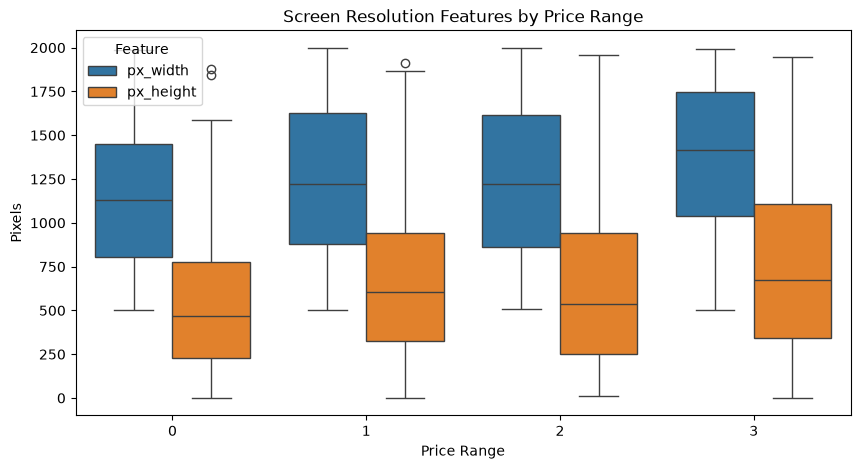

In [12]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=train_df.melt(
        id_vars="price_range",
        value_vars=["px_width", "px_height"],
        var_name="Feature",
        value_name="Pixels"
    ),
    x="price_range",
    y="Pixels",
    hue="Feature"
)

plt.title("Screen Resolution Features by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Pixels")
plt.show()

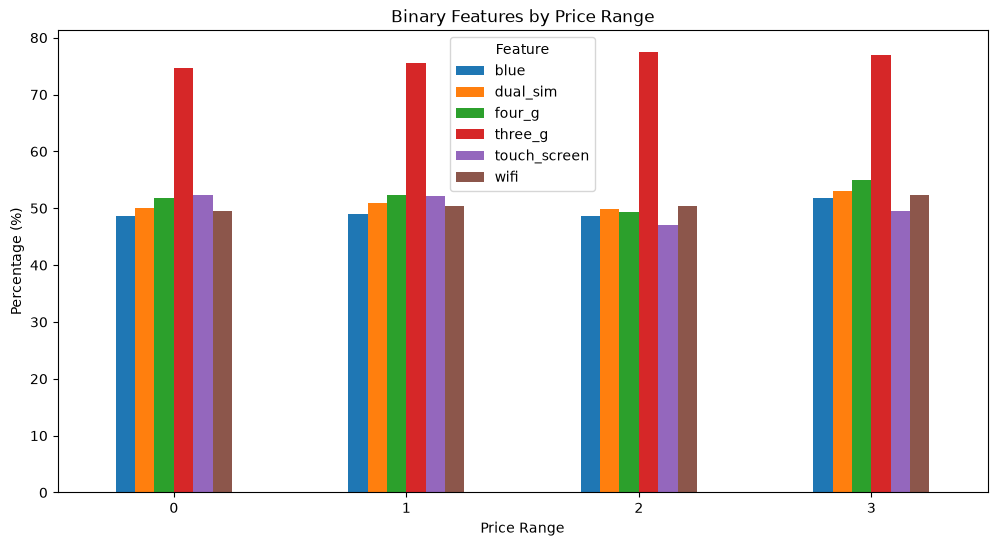

In [13]:
binary_features = [
    "blue",
    "dual_sim",
    "four_g",
    "three_g",
    "touch_screen",
    "wifi"
]

binary_rates = train_df.groupby("price_range")[binary_features].mean() * 100

binary_rates.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Binary Features by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Feature")
plt.show()

**Corrélations** : plus la couleur est foncée (rouge ou bleu), plus le lien entre deux variables est fort. Regarde la ligne `price_range` : `ram` ressort très nettement.

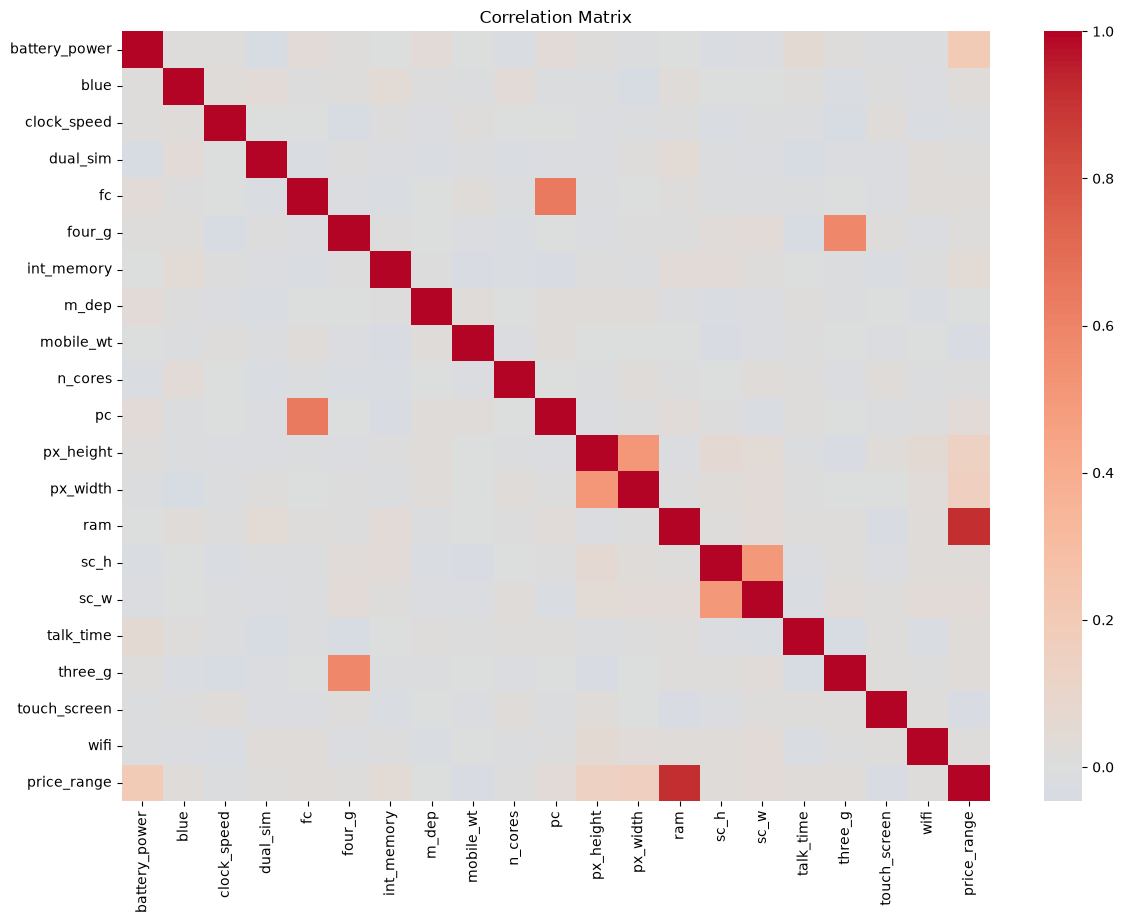

In [14]:
plt.figure(figsize=(14, 10))

correlation_matrix = train_df.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Matrix")
plt.show()

## 3. Séparation entraînement / validation

On garde 20 % des données de côté (**validation**) .On les utilise à la fin pour mesurer sa vraie performance.

- `stratify=y` : garde la même proportion de chaque classe dans les deux jeux
- `random_state=42` : rend le découpage reproductible

In [15]:
X = train_df.drop(columns=["price_range"])
y = train_df["price_range"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Features shape: (2000, 20)
Target shape: (2000,)


## 4. Modèles de base (avant optimisation)

On entraîne trois modèles avec leurs réglages par défaut. Ils servent de **point de comparaison**.

- **Régression logistique** : modèle simple, avec standardisation des données (`StandardScaler`).
- **Arbre de décision** : une série de questions « oui / non ».
- **Random Forest** : beaucoup d'arbres qui votent ensemble.

In [16]:
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])
dt_model = DecisionTreeClassifier(random_state=42)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

for model in (lr_model, dt_model, rf_model):
    model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_val)
y_pred_dt = dt_model.predict(X_val)
y_pred_rf = rf_model.predict(X_val)

Résultats des modèles de base sur le jeu de validation :

In [17]:
results_before = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_val, y_pred_lr),
        accuracy_score(y_val, y_pred_dt),
        accuracy_score(y_val, y_pred_rf)
    ],
    "F1-score (macro)": [
        f1_score(y_val, y_pred_lr, average="macro"),
        f1_score(y_val, y_pred_dt, average="macro"),
        f1_score(y_val, y_pred_rf, average="macro")
    ]
})

results_before = results_before.sort_values("Accuracy", ascending=False)
results_before

,Model,Accuracy,F1-score (macro)
0,Logistic Regression,0.965,0.964986
2,Random Forest,0.880,0.879734
1,Decision Tree,0.830,0.830168


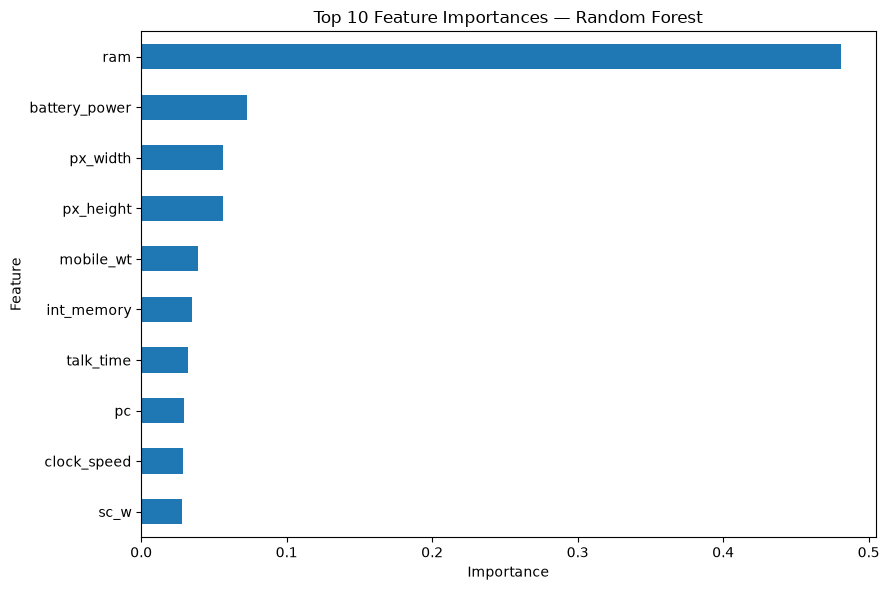

In [18]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

feature_importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Top 10 Feature Importances — Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

`ram` domine très largement (environ 48 % de l'importance totale), puis viennent la batterie et la résolution. Cela confirme ce qu'on a vu dans l'EDA.

## 5. Optimisation des hyperparamètres (`GridSearchCV`)

Les hyperparamètres sont les réglages d'un modèle (profondeur d'un arbre, nombre d'arbres, etc.). `GridSearchCV` teste toutes les combinaisons d'une grille et garde la meilleure.

Deux points importants :
- La recherche se fait **uniquement sur le jeu d'entraînement**, avec une validation croisée à 5 folds (`cv=5`). Le jeu de validation reste intact pour le test final.
- On optimise le `f1_macro`, qui traite les 4 classes de manière égale.

### Régression logistique

On règle `C` : plus il est grand, moins le modèle est contraint.

In [19]:
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

lr_params = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

lr_grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_params,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

print("Best parameters:", lr_grid.best_params_)
print("Best CV F1-score:", round(lr_grid.best_score_, 4))

# Best model found by GridSearchCV
best_lr = lr_grid.best_estimator_

# Prediction on the validation set
y_pred_lr_tuned = best_lr.predict(X_val)

# Evaluation
print(f"Accuracy: {accuracy_score(y_val, y_pred_lr_tuned):.4f}")
print(classification_report(y_val, y_pred_lr_tuned))

Best parameters: {'model__C': 100}
Best CV F1-score: 0.9612
Accuracy: 0.9825
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       100
           1       0.99      0.97      0.98       100
           2       0.96      0.98      0.97       100
           3       0.99      0.98      0.98       100

    accuracy                           0.98       400
   macro avg       0.98      0.98      0.98       400
weighted avg       0.98      0.98      0.98       400



### Arbre de décision

In [20]:
dt_params = {
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "ccp_alpha": [0.0, 0.001, 0.005, 0.01]
}

dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=dt_params,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Best parameters:", dt_grid.best_params_)
print("Best CV F1-score:", round(dt_grid.best_score_, 4))

best_dt = dt_grid.best_estimator_

y_pred_dt_tuned = best_dt.predict(X_val)

print("Accuracy:", round(accuracy_score(y_val, y_pred_dt_tuned), 4))
print("\nClassification Report:")
print(classification_report(y_val, y_pred_dt_tuned))

Best parameters: {'ccp_alpha': 0.001, 'max_depth': None, 'min_samples_leaf': 2}
Best CV F1-score: 0.8358
Accuracy: 0.8325

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.92      0.90       100
           1       0.78      0.75      0.77       100
           2       0.75      0.79      0.77       100
           3       0.92      0.87      0.89       100

    accuracy                           0.83       400
   macro avg       0.83      0.83      0.83       400
weighted avg       0.83      0.83      0.83       400



### Random Forest

In [21]:
rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.8]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=rf_params,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best parameters:", rf_grid.best_params_)
print("Best CV F1-score:", round(rf_grid.best_score_, 4))

best_rf = rf_grid.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_val)

print("Accuracy:", round(accuracy_score(y_val, y_pred_rf_tuned), 4))
print("\nClassification Report:")
print(classification_report(y_val, y_pred_rf_tuned))

Best parameters: {'max_depth': 10, 'max_features': 0.8, 'min_samples_leaf': 1, 'n_estimators': 100}
Best CV F1-score: 0.8843
Accuracy: 0.91

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95       100
           1       0.88      0.86      0.87       100
           2       0.86      0.89      0.87       100
           3       0.96      0.94      0.95       100

    accuracy                           0.91       400
   macro avg       0.91      0.91      0.91       400
weighted avg       0.91      0.91      0.91       400



## 6. Comparaison finale

### Avant / après optimisation (jeu de validation)

In [22]:
# Prédictions avant et après optimisation
preds_before = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
}
preds_after = {
    "Logistic Regression": y_pred_lr_tuned,
    "Decision Tree": y_pred_dt_tuned,
    "Random Forest": y_pred_rf_tuned,
}

comparison = pd.DataFrame({
    "Model": list(preds_before),
    "Accuracy avant": [accuracy_score(y_val, p) for p in preds_before.values()],
    "Accuracy après": [accuracy_score(y_val, p) for p in preds_after.values()],
    "F1 macro après": [f1_score(y_val, p, average="macro") for p in preds_after.values()],
})
comparison["Gain"] = comparison["Accuracy après"] - comparison["Accuracy avant"]

comparison = comparison.sort_values("Accuracy après", ascending=False).reset_index(drop=True)
comparison.round(4)

,Model,Accuracy avant,Accuracy après,F1 macro après,Gain
0,Logistic Regression,0.965,0.9825,0.9825,0.0175
1,Random Forest,0.880,0.9100,0.9102,0.0300
2,Decision Tree,0.830,0.8325,0.8326,0.0025


### Matrice de confusion : régression logistique optimisée

La diagonale (en foncé) montre les prédictions correctes ; le reste, les erreurs.

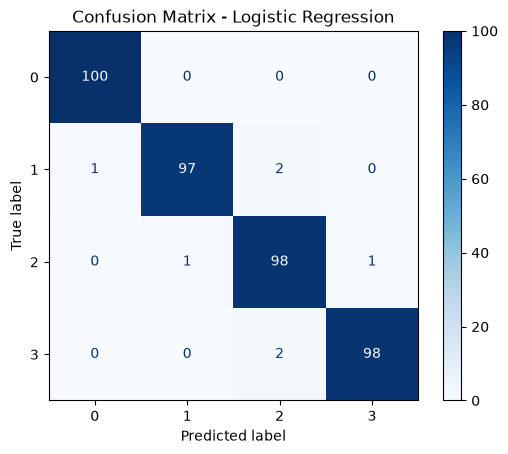

In [23]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_lr_tuned,
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

Sur 400 téléphones, **393 sont bien classés et 7 seulement sont mal classés**. Toutes les erreurs concernent des **classes voisines** (1↔0, 1↔2, 2↔3...) : le modèle ne se trompe jamais de beaucoup, ce qui est logique car deux gammes de prix voisines se ressemblent.

### Validation croisée du modèle final

Les scores ci-dessus viennent d'**un seul découpage** (400 exemples de validation). La validation croisée répète l'évaluation 5 fois avec des découpages différents pour vérifier que le résultat est **stable** et pas dû à la chance.

- **Moyenne** : performance attendue.
- **Écart-type** : plus il est petit, plus le modèle est stable.

*Remarque : les hyperparamètres ayant été choisis avec une partie de ces données, ces scores sont très légèrement optimistes. C'est acceptable pour ce projet.*

In [24]:
# Les 3 modèles optimisés, évalués par validation croisée (5 folds) sur TOUTES les données
best_models = {
    "Logistic Regression": best_lr,
    "Decision Tree": best_dt,
    "Random Forest": best_rf,
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for name, model in best_models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="f1_macro")
    cv_rows.append({
        "Model": name,
        "F1 macro (moyenne)": scores.mean(),
        "Écart-type": scores.std(),
        "Min": scores.min(),
        "Max": scores.max(),
    })

cv_results = pd.DataFrame(cv_rows).sort_values("F1 macro (moyenne)", ascending=False).reset_index(drop=True)
cv_results.round(4)

,Model,F1 macro (moyenne),Écart-type,Min,Max
0,Logistic Regression,0.9715,0.0071,0.9625,0.9825
1,Random Forest,0.8904,0.0186,0.8678,0.9102
2,Decision Tree,0.8452,0.0195,0.8209,0.8752


## 7. Conclusion

- **Meilleur modèle : la régression logistique optimisée**, avec **98,25 %** d'accuracy sur le jeu de validation (393 prédictions correctes sur 400). La validation croisée ci-dessus permet de vérifier la stabilité de ce score.
- **Pourquoi un modèle simple gagne ?** Dans ce dataset, le prix dépend de manière presque linéaire des caractéristiques, surtout de la RAM. Un modèle linéaire suffit, alors que les arbres, qui découpent les données par paliers, sont moins adaptés.
- **Effet de l'optimisation :** gain de +1,75 point pour la régression logistique (96,5 % → 98,25 %) et de +3 points pour le Random Forest (88 % → 91 %). L'arbre de décision progresse à peine (83 % → 83,25 %).
- **Variable la plus importante :** la **RAM**, de très loin.
- **Erreurs :** peu nombreuses et toujours entre gammes de prix voisines.

## 8. Sauvegarder le modèle et prédire sur `test.csv`

On réentraîne le meilleur modèle sur **toutes** les données, on le sauvegarde, puis on prédit la gamme de prix des téléphones de `test.csv`

In [25]:
# 1. On réentraîne le meilleur modèle sur TOUTES les données labellisées
final_model = clone(best_lr)
final_model.fit(X, y)

# 2. On sauvegarde le modèle pour pouvoir le réutiliser sans réentraîner
joblib.dump(final_model, "best_model_logistic_regression.joblib")

# 3. On prédit la gamme de prix des téléphones de test.csv
test_df = pd.read_csv("data/test.csv")
test_features = test_df.drop(columns=["id"], errors="ignore")[X.columns]

predictions = final_model.predict(test_features)

output = pd.DataFrame({"predicted_price_range": predictions})
if "id" in test_df.columns:
    output.insert(0, "id", test_df["id"])

output.to_csv("test_predictions.csv", index=False)
output.head()

,id,predicted_price_range
0,1,3
1,2,3
2,3,2
3,4,3
4,5,1
